In [1]:
from pathlib import Path
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"

print("Dataset path:", WHITEBOARD_PATH)
print("Dataset exists:", WHITEBOARD_PATH.exists())


C:\Users\skand\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Dataset path: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\datasets\whiteboard
Dataset exists: True


In [2]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

splits = ["train", "valid", "test"]

for split in splits:

    image_dir = WHITEBOARD_PATH / split / "images"
    label_dir = WHITEBOARD_PATH / split / "labels"

    images = [
        f for f in image_dir.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    labels = list(label_dir.glob("*.txt"))

    image_names = {f.stem for f in images}
    label_names = {f.stem for f in labels}

    missing_labels = image_names - label_names
    extra_labels = label_names - image_names

    print(f"\n{split.upper()} DATASET")
    print("-" * 35)
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(extra_labels))


TRAIN DATASET
-----------------------------------
Images: 7093
Labels: 7093
Images without labels: 0
Labels without images: 0

VALID DATASET
-----------------------------------
Images: 695
Labels: 695
Images without labels: 0
Labels without images: 0

TEST DATASET
-----------------------------------
Images: 557
Labels: 557
Images without labels: 0
Labels without images: 0


In [3]:
def validate_yolo_annotations(split):
    label_dir = WHITEBOARD_PATH / split / 'labels'
    valid_bboxes = 0
    valid_polygons = 0
    invalid_count = 0
    empty_count = 0

    for label_file in label_dir.glob('*.txt'):
        lines = label_file.read_text().strip().splitlines()
        if not lines or not any(line.strip() for line in lines):
            empty_count += 1
            continue

        for line in lines:
            values = line.split()
            try:
                values = list(map(float, values))
                if not all(np.isfinite(v) for v in values):
                    raise ValueError('Non-finite values')
                if values[0] < 0 or not values[0].is_integer():
                    raise ValueError('Invalid class ID')

                if len(values) == 5:
                    # Bounding box: class cx cy w h
                    if not all(0 <= v <= 1 for v in values[1:]):
                        raise ValueError('Coordinates outside 0-1')
                    valid_bboxes += 1
                elif len(values) >= 7 and (len(values) - 1) % 2 == 0:
                    # Polygon
                    coordinates = values[1:]
                    if not all(0 <= v <= 1 for v in coordinates):
                        raise ValueError('Coordinates outside 0-1')
                    valid_polygons += 1
                else:
                    raise ValueError(f'Unsupported coordinate length ({len(values)})')
            except ValueError as error:
                invalid_count += 1
                print(f'Problem in {label_file.name}: {error}')

    print(f'\n{split.upper()} ANNOTATION REPORT')
    print('Valid bounding boxes:', valid_bboxes)
    print('Valid polygons:', valid_polygons)
    print('Invalid annotations:', invalid_count)
    print('Empty annotation files:', empty_count)

for split in splits:
    validate_yolo_annotations(split)



TRAIN ANNOTATION REPORT
Valid bounding boxes: 14961
Valid polygons: 13640
Invalid annotations: 0
Empty annotation files: 885

VALID ANNOTATION REPORT
Valid bounding boxes: 1293
Valid polygons: 1165
Invalid annotations: 0
Empty annotation files: 85

TEST ANNOTATION REPORT
Valid bounding boxes: 725
Valid polygons: 737
Invalid annotations: 0
Empty annotation files: 75


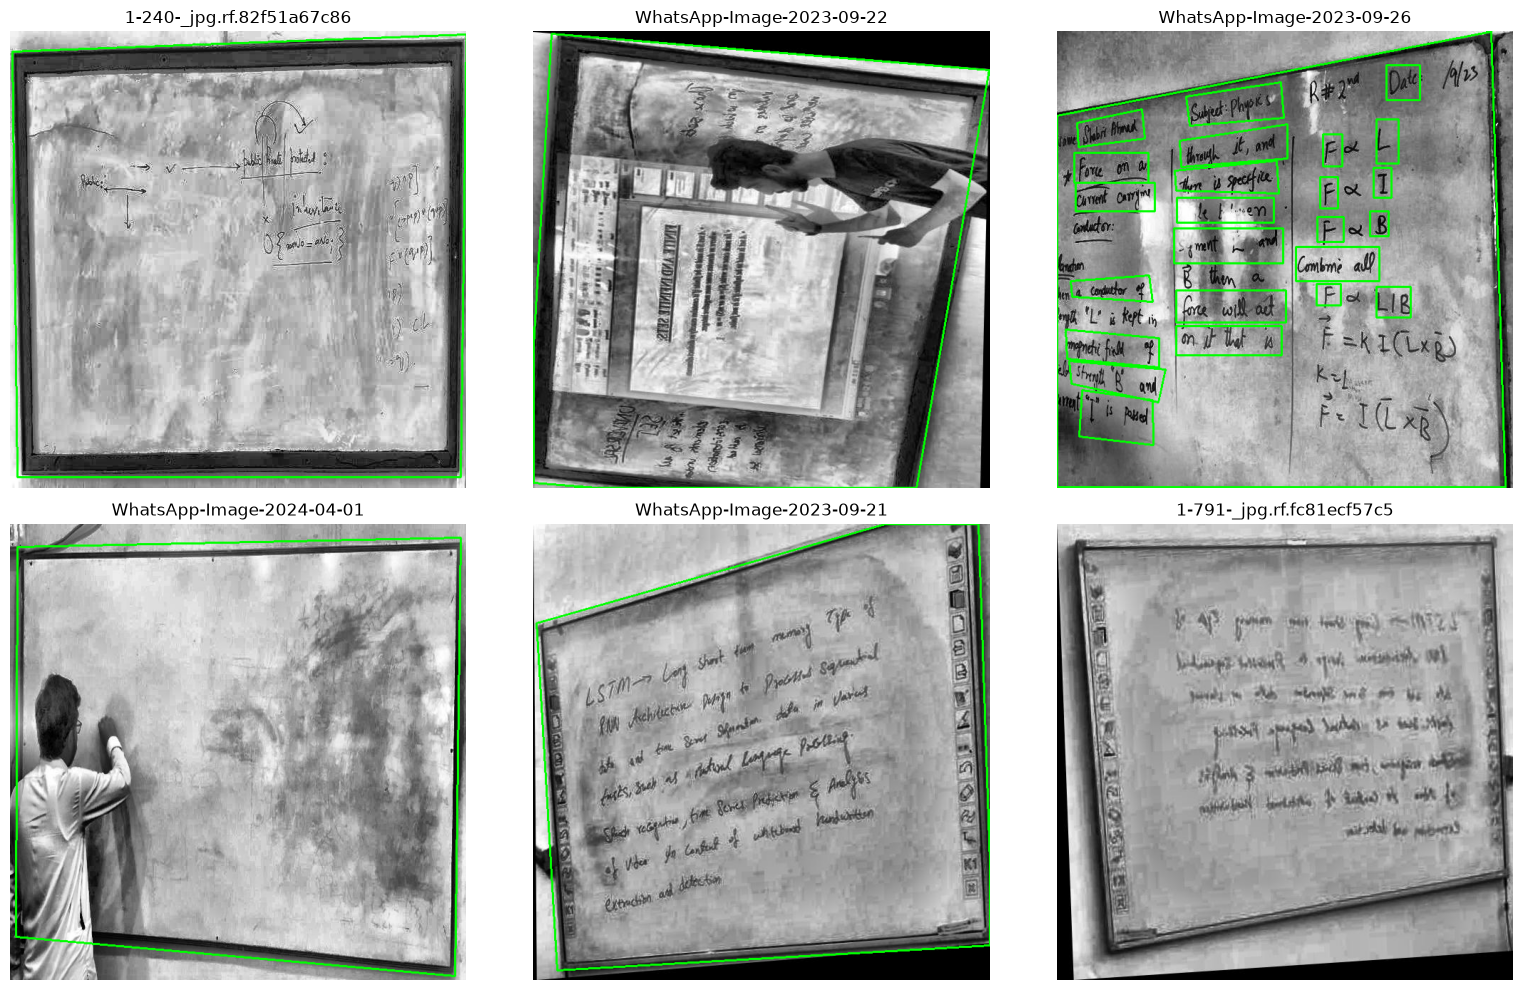

In [4]:
import random

train_images = WHITEBOARD_PATH / 'train' / 'images'
train_labels = WHITEBOARD_PATH / 'train' / 'labels'

image_files = [
    f for f in train_images.iterdir()
    if f.suffix.lower() in image_extensions
]

selected_images = random.sample(
    image_files,
    min(6, len(image_files))
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):
    image = cv2.imread(str(image_path))
    if image is None:
        continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    label_path = train_labels / f'{image_path.stem}.txt'

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue
            values = list(map(float, line.split()))
            if len(values) == 5:
                cx, cy, w, h = values[1:]
                x1 = int((cx - w / 2) * width)
                y1 = int((cy - h / 2) * height)
                x2 = int((cx + w / 2) * width)
                y2 = int((cy + h / 2) * height)
                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
            elif len(values) >= 7 and (len(values) - 1) % 2 == 0:
                points = np.array(values[1:]).reshape(-1, 2)
                points[:, 0] *= width
                points[:, 1] *= height
                points = points.astype(np.int32)
                cv2.polylines(image, [points], True, (0, 255, 0), 2)

    ax.imshow(image)
    ax.set_title(image_path.name[:25])
    ax.axis('off')

for ax in axes[len(selected_images):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [5]:
yaml_path = WHITEBOARD_PATH / "data.yaml"

with open(yaml_path, "r") as file:
    dataset_config = yaml.safe_load(file)

print(dataset_config)

{'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 2, 'names': ['Handwritten text', 'Whiteboard'], 'roboflow': {'workspace': 'university-of-peshawar-4qet5', 'project': 'new-dataset-xjgtk', 'version': 12, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/university-of-peshawar-4qet5/new-dataset-xjgtk/dataset/12'}}


In [6]:
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

Ultralytics: 8.4.211
PyTorch: 2.15.0+cpu
CUDA available: False
Using CPU
